# Experiment 006: 0.5B SFT-to-GRPO three-seed analysis plots

All three A100/BF16 seeds are now complete. This notebook checks each run first, then
keeps two different levels of evidence separate:

- Paired item comparisons describe a particular trained artifact;
- The three seed endpoints show how much the training procedure varies.

Experiment 005 remains the matched seed-0 base+GRPO comparison for RQ3. Experiment 006
seeds 1 and 2 are useful sensitivity evidence, but they are not matched RQ3 contrasts because
experiment 005 has no corresponding seeds. Experiment 002 stays as earlier T4/FP16 context.

Figures are saved to `analysis/figures/006_1/` as 300 dpi PNG files.


In [76]:
# load all three 006 seeds and keep the artifact checks in one place
import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "config.py").exists():
    raise FileNotFoundError("I could not find the repository root containing config.py")
sys.path.insert(0, str(ROOT))

from analysis.stats import align_pred_rows, holm, mcnemar_exact, paired_delta_ci
from data.subjects import TIERS as VALIDATED_TIERS
from eval.metrics import bootstrap_ci

RES = ROOT / "results"
R2 = RES / "002_COLAB_FULL_B05_sft_grpo_seed0"
R3 = {seed: RES / f"003_COLAB_FULL_B3_sft_grpo_seed{seed}" for seed in (0, 1)}
R4 = RES / "004_COLAB_FULL_B3_base_grpo_seed0"
R5 = RES / "005_COLAB_FULL_B05_base_grpo_seed0"
B5 = RES / "base_evals" / "005_COLAB_FULL_B05"
SEEDS = (0, 1, 2)
R6 = {seed: RES / f"006_COLAB_FULL_B05_sft_grpo_seed{seed}" for seed in SEEDS}
B6 = RES / "base_evals" / "006_COLAB_FULL_B05"
FIG = ROOT / "analysis" / "figures" / "006_1"
FIG.mkdir(parents=True, exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")
COLORS = {
    "base": "#4C78A8",
    "sft": "#54A24B",
    "grpo": "#F58518",
    "other": "#B279A2",
    "old": "#9D9DA1",
}
SEED_COLORS = {0: "#4C78A8", 1: "#F58518", 2: "#54A24B"}
SEED_STYLES = {0: "-", 1: "--", 2: "-."}
TIER_COLORS = {"easy": "#59A14F", "medium": "#F28E2B", "hard": "#E15759"}
TIERS = ["easy", "medium", "hard"]
GROUPS = TIERS + ["overall"]
TIER_LOOKUP = {subject: tier for tier, subjects in VALIDATED_TIERS.items() for subject in subjects}
CONDITIONS = ["base", "sft", "grpo"]
CONDITION_LABELS = {"base": "base", "sft": "SFT", "grpo": "SFT + GRPO"}
EXPECTED = {
    "sft_eval.json", "sft_logprob.json", "sft_preds.jsonl", "sft_logprob_preds.jsonl",
    "sft_trainlog.json", "grpo_eval.json", "grpo_logprob.json", "grpo_preds.jsonl",
    "grpo_logprob_preds.jsonl", "grpo_trainlog.json", "summary.json", "manifest.json", "run.log",
}

def jload(path):
    with open(path) as handle:
        return json.load(handle)

def jsonl(path):
    with open(path) as handle:
        rows = [json.loads(line) for line in handle if line.strip()]
    return [{**row, "tier": TIER_LOOKUP[row["subject"]]} for row in rows]

def series(trainlog, key):
    rows = [row for row in trainlog if key in row and "step" in row]
    return np.asarray([row["step"] for row in rows]), np.asarray([row[key] for row in rows], dtype=float)

def smooth(values, window=20):
    if len(values) < window:
        return values
    return np.convolve(values, np.ones(window) / window, mode="valid")

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    print("saved", name)

def accuracy(rows):
    return float(np.mean([bool(row["correct"]) for row in rows]))

def group_rows(rows, group):
    return rows if group == "overall" else [row for row in rows if row["tier"] == group]

def group_accuracy(rows, group):
    return accuracy(group_rows(rows, group))

def group_ci(rows, group, seed):
    selected = group_rows(rows, group)
    return bootstrap_ci([row["pred"] for row in selected], [row["gold"] for row in selected], seed=seed)

def overall(data, condition, probe=False):
    bucket = "lp_preds" if probe else "preds"
    return accuracy(data[bucket][condition])

def edge_mean(trainlog, key, first=True, count=50):
    values = [float(row[key]) for row in trainlog if key in row and "step" in row]
    part = values[:count] if first else values[-count:]
    return float(np.mean(part))

def paired_correct(rows_a, rows_b, tier=None):
    rows_a, rows_b = align_pred_rows(rows_a, rows_b)
    if tier is not None:
        rows_a = [row for row in rows_a if row["tier"] == tier]
        rows_b = [row for row in rows_b if row["tier"] == tier]
    if len(rows_a) != len(rows_b):
        raise ValueError("I found different numbers of paired predictions")
    for row_a, row_b in zip(rows_a, rows_b):
        if (row_a["subject"], row_a["tier"], row_a["gold"]) != (row_b["subject"], row_b["tier"], row_b["gold"]):
            raise ValueError("I found prediction rows that are not aligned")
    return [bool(row["correct"]) for row in rows_a], [bool(row["correct"]) for row in rows_b]

def paired_stats(rows_a, rows_b, seed):
    output = []
    for group in GROUPS:
        tier = None if group == "overall" else group
        correct_a, correct_b = paired_correct(rows_a, rows_b, tier=tier)
        delta, lo, hi = paired_delta_ci(correct_a, correct_b, seed=seed)
        a_only = sum(a and not b for a, b in zip(correct_a, correct_b))
        b_only = sum((not a) and b for a, b in zip(correct_a, correct_b))
        output.append({
            "group": group,
            "delta": delta,
            "ci_lo": lo,
            "ci_hi": hi,
            "a_only": a_only,
            "b_only": b_only,
            "mcnemar_p": mcnemar_exact(a_only, b_only),
        })
    adjusted = holm([row["mcnemar_p"] for row in output[:3]])
    for row, value in zip(output[:3], adjusted):
        row["holm_p_tiers"] = value
    output[-1]["holm_p_tiers"] = np.nan
    return output

def outcome_parts(rows):
    n = len(rows)
    return {
        "correct + full format": sum(row["correct"] and row["format_ok"] for row in rows) / n,
        "correct, no full format": sum(row["correct"] and not row["format_ok"] for row in rows) / n,
        "wrong but extracted": sum((not row["correct"]) and row["pred"] is not None for row in rows) / n,
        "no extracted answer": sum(row["pred"] is None for row in rows) / n,
    }

def parse_run_timings(path):
    pattern = re.compile(
        r"INFO (base_eval|base_logprob_eval|sft train|sft_eval|sft_logprob_eval|grpo train|grpo_eval|grpo_logprob_eval) "
        r"done in (?:(\d+)h )?(?:(\d+)m )?(\d+)s"
    )
    found = {}
    for line in path.read_text().splitlines():
        match = pattern.search(line)
        if match:
            stage, hours, minutes, seconds = match.groups()
            found[stage.replace(" ", "_")] = int(hours or 0) * 3600 + int(minutes or 0) * 60 + int(seconds)
    return found

def load_sft_grpo(run_dir, base_dir):
    return {
        "g": jload(run_dir / "grpo_trainlog.json"),
        "s": jload(run_dir / "sft_trainlog.json"),
        "eval": {condition: jload((base_dir if condition == "base" else run_dir) / f"{condition}_eval.json") for condition in CONDITIONS},
        "lp": {condition: jload((base_dir if condition == "base" else run_dir) / f"{condition}_logprob.json") for condition in CONDITIONS},
        "preds": {condition: jsonl((base_dir if condition == "base" else run_dir) / f"{condition}_preds.jsonl") for condition in CONDITIONS},
        "lp_preds": {condition: jsonl((base_dir if condition == "base" else run_dir) / f"{condition}_logprob_preds.jsonl") for condition in CONDITIONS},
        "man": jload(run_dir / "manifest.json"),
        "summary": jload(run_dir / "summary.json"),
    }

def load_base_grpo(run_dir, base_dir):
    return {
        "g": jload(run_dir / "grpo_trainlog.json"),
        "eval": {"base": jload(base_dir / "base_eval.json"), "grpo": jload(run_dir / "grpo_eval.json")},
        "lp": {"base": jload(base_dir / "base_logprob.json"), "grpo": jload(run_dir / "grpo_logprob.json")},
        "preds": {"base": jsonl(base_dir / "base_preds.jsonl"), "grpo": jsonl(run_dir / "grpo_preds.jsonl")},
        "lp_preds": {"base": jsonl(base_dir / "base_logprob_preds.jsonl"), "grpo": jsonl(run_dir / "grpo_logprob_preds.jsonl")},
        "man": jload(run_dir / "manifest.json"),
    }

def load_endpoint(run_dir):
    return {
        "g": jload(run_dir / "grpo_trainlog.json"),
        "eval": {"grpo": jload(run_dir / "grpo_eval.json")},
        "lp": {"grpo": jload(run_dir / "grpo_logprob.json")},
        "preds": {"grpo": jsonl(run_dir / "grpo_preds.jsonl")},
        "lp_preds": {"grpo": jsonl(run_dir / "grpo_logprob_preds.jsonl")},
        "man": jload(run_dir / "manifest.json"),
    }

D6 = {seed: load_sft_grpo(R6[seed], B6) for seed in SEEDS}
D5 = load_base_grpo(R5, B5)
D2 = load_endpoint(R2)
D3 = {seed: load_endpoint(R3[seed]) for seed in (0, 1)}
D4 = load_endpoint(R4)
RUN_TIMINGS = {seed: parse_run_timings(R6[seed] / "run.log") for seed in SEEDS}
MISSING = {seed: sorted(name for name in EXPECTED if not (R6[seed] / name).exists()) for seed in SEEDS}

for seed in SEEDS:
    paired_correct(D6[seed]["preds"]["sft"], D6[seed]["preds"]["grpo"])
    assert len([row for row in D6[seed]["g"] if "reward" in row]) == 500
    assert all(D6[seed]["eval"][condition]["n_items"] == 1884 for condition in CONDITIONS)
    assert D6[seed]["man"]["resolved_dtype"] == "bfloat16"
    assert "A100" in D6[seed]["man"]["gpu"]["device"]
    assert D6[seed]["man"]["git"]["dirty"] is False
    assert not MISSING[seed]

assert all(D6[seed]["preds"]["base"] == D5["preds"]["base"] for seed in SEEDS)
for section in ["lora", "reward", "grpo"]:
    assert all(D6[seed]["man"]["config"][section] == D6[0]["man"]["config"][section] for seed in SEEDS)
for key in ["sft_lr", "grpo_lr", "max_steps", "num_generations", "max_seq_len", "sft_batch_size", "sft_grad_accum", "sft_completion_only", "sft_val_examples"]:
    assert all(D6[seed]["man"]["config"]["train"][key] == D6[0]["man"]["config"]["train"][key] for seed in SEEDS)
assert {D6[seed]["man"]["seed"] for seed in SEEDS} == set(SEEDS)

print("loaded and checked experiment 006 seeds 0, 1 and 2")
print("figures ->", FIG)


loaded and checked experiment 006 seeds 0, 1 and 2
figures -> /Users/oleggastov/Desktop/University UK/0006_City n St Georges Universities/003_Projects/INM363-IndividualProject-Dissertation/001_Code/analysis/figures/006_1


## 1. Run health

All three runs reached 500 steps and completed every evaluation. Seed 0 resumed only for its final
evaluation, so its manifest contains partial process timing. `run.log` is used for complete stage
timing across seeds. The 3.353 GB value in seed 0 is therefore not treated as training peak VRAM.


In [77]:
# separate completed work from the known seed 0 resume logging gap
health_rows = []
for seed in SEEDS:
    data = D6[seed]
    manifest_timings = data["man"].get("timings_sec", {})
    health_rows.append({
        "seed": seed,
        "completed_grpo_steps": len([row for row in data["g"] if "reward" in row]),
        "eval_items_per_stage": data["eval"]["grpo"]["n_items"],
        "missing_artifacts": len(MISSING[seed]),
        "gpu": data["man"]["gpu"]["device"],
        "dtype": data["man"]["resolved_dtype"],
        "git_commit": data["man"]["git"]["commit"][:7],
        "git_clean": not data["man"]["git"]["dirty"],
        "stage_hours_from_log": sum(RUN_TIMINGS[seed].values()) / 3600,
        "manifest_has_full_timing": set(RUN_TIMINGS[seed]) <= set(manifest_timings),
        "manifest_peak_vram_gb": data["man"]["gpu"]["peak_vram_gb"],
    })
health_tbl = pd.DataFrame(health_rows).set_index("seed").round(3)
display(health_tbl)


,completed_grpo_steps,eval_items_per_stage,missing_artifacts,gpu,dtype,git_commit,git_clean,stage_hours_from_log,manifest_has_full_timing,manifest_peak_vram_gb
seed,,,,,,,,,,
0,500,1884,0,NVIDIA A100-SXM4-40GB,bfloat16,88dae72,True,6.613,False,3.353
1,500,1884,0,NVIDIA A100-SXM4-40GB,bfloat16,99550b5,True,6.562,True,21.644
2,500,1884,0,NVIDIA A100-SXM4-40GB,bfloat16,77f80d9,True,5.597,True,21.644


saved fig01_training_rewards


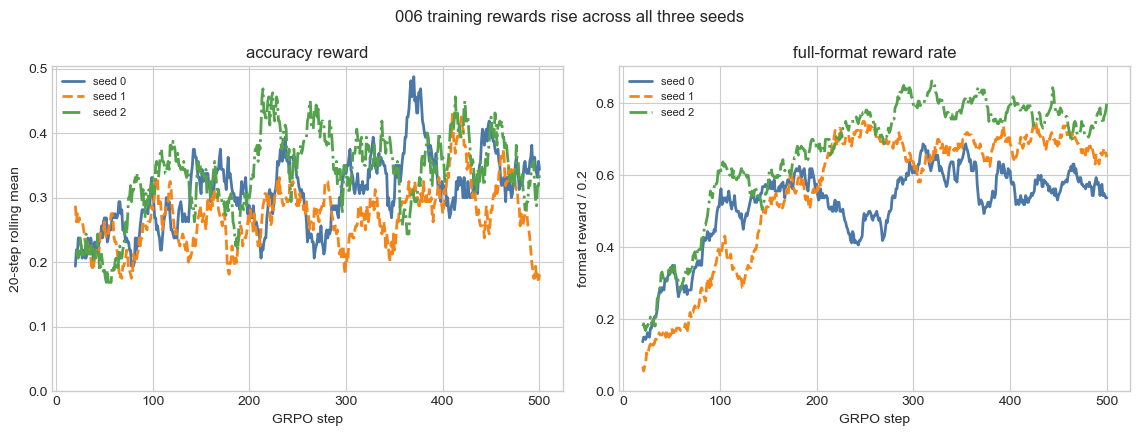

In [78]:
# plot both reward channels across all 500 steps for all three seeds
window = 20
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
for seed in SEEDS:
    x, values = series(D6[seed]["g"], "rewards/accuracy_reward/mean")
    axes[0].plot(x[window - 1:], smooth(values, window), color=SEED_COLORS[seed],
                 ls=SEED_STYLES[seed], lw=2, label=f"seed {seed}")
    x, values = series(D6[seed]["g"], "rewards/format_reward/mean")
    axes[1].plot(x[window - 1:], smooth(values / 0.2, window), color=SEED_COLORS[seed],
                 ls=SEED_STYLES[seed], lw=2, label=f"seed {seed}")
axes[0].set_title("accuracy reward")
axes[0].set_ylabel("20-step rolling mean")
axes[1].set_title("full-format reward rate")
axes[1].set_ylabel("format reward / 0.2")
for ax in axes:
    ax.set_xlabel("GRPO step")
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=8)
fig.suptitle("006 training rewards rise across all three seeds")
fig.tight_layout()
save(fig, "fig01_training_rewards")
plt.show()


saved fig02_kl_and_reward_variation


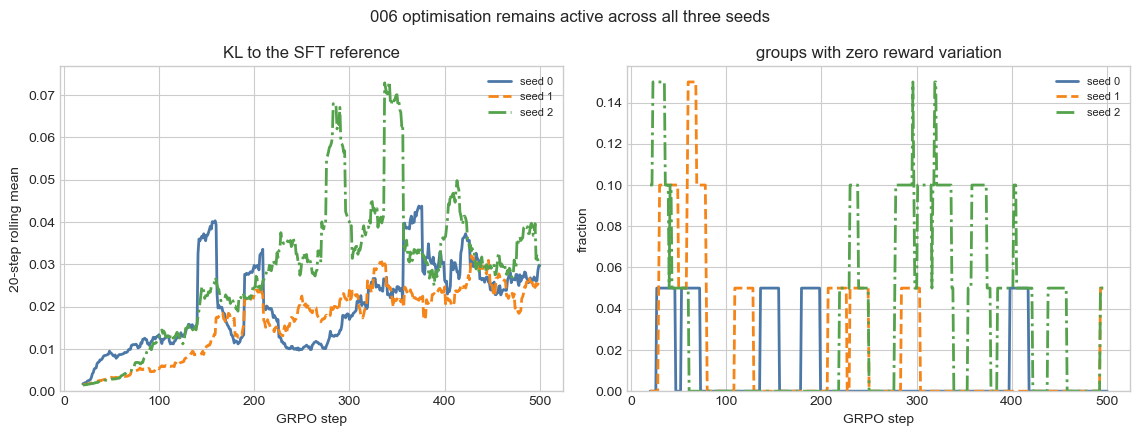

In [79]:
# compare policy movement and reward variation across seeds
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
for seed in SEEDS:
    x, values = series(D6[seed]["g"], "kl")
    axes[0].plot(x[window - 1:], smooth(values, window), color=SEED_COLORS[seed],
                 ls=SEED_STYLES[seed], lw=2, label=f"seed {seed}")
    x, values = series(D6[seed]["g"], "frac_reward_zero_std")
    axes[1].plot(x[window - 1:], smooth(values, window), color=SEED_COLORS[seed],
                 ls=SEED_STYLES[seed], lw=2, label=f"seed {seed}")
axes[0].set_title("KL to the SFT reference")
axes[0].set_ylabel("20-step rolling mean")
axes[1].set_title("groups with zero reward variation")
axes[1].set_ylabel("fraction")
for ax in axes:
    ax.set_xlabel("GRPO step")
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=8)
fig.suptitle("006 optimisation remains active across all three seeds")
fig.tight_layout()
save(fig, "fig02_kl_and_reward_variation")
plt.show()


saved fig03_length_and_clipping


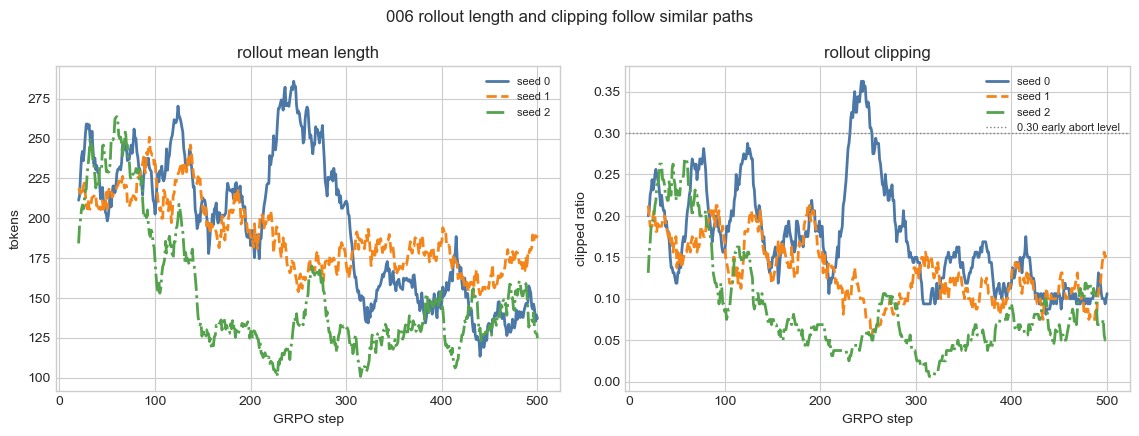

In [80]:
# check rollout length and clipping for all three seeds
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
for seed in SEEDS:
    x, values = series(D6[seed]["g"], "completions/mean_length")
    axes[0].plot(x[window - 1:], smooth(values, window), color=SEED_COLORS[seed],
                 ls=SEED_STYLES[seed], lw=2, label=f"seed {seed}")
    x, values = series(D6[seed]["g"], "completions/clipped_ratio")
    axes[1].plot(x[window - 1:], smooth(values, window), color=SEED_COLORS[seed],
                 ls=SEED_STYLES[seed], lw=2, label=f"seed {seed}")
axes[1].axhline(0.3, color="grey", ls=":", lw=1, label="0.30 early abort level")
axes[0].set_title("rollout mean length")
axes[0].set_ylabel("tokens")
axes[1].set_title("rollout clipping")
axes[1].set_ylabel("clipped ratio")
for ax in axes:
    ax.set_xlabel("GRPO step")
    ax.legend(fontsize=8)
fig.suptitle("006 rollout length and clipping follow similar paths")
fig.tight_layout()
save(fig, "fig03_length_and_clipping")
plt.show()


saved fig04_sft_train_val_loss


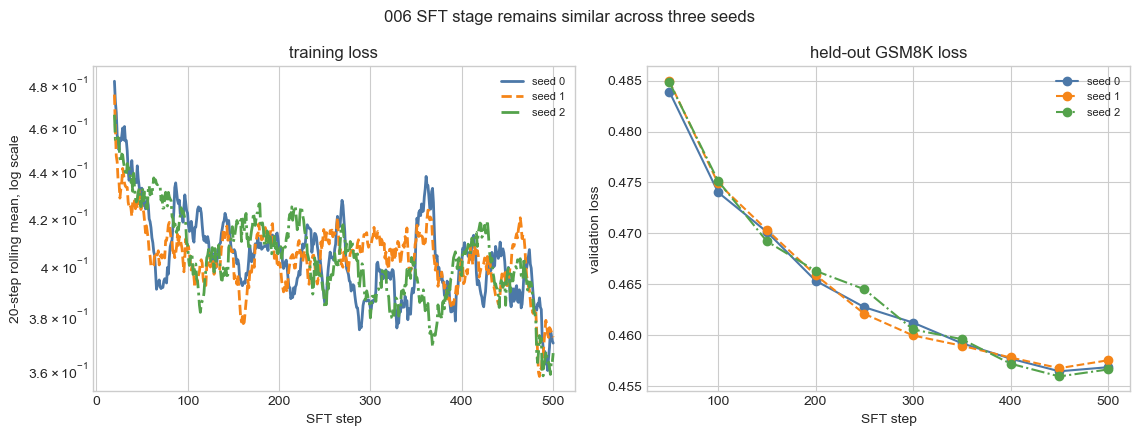

In [81]:
# compare SFT training and validation loss across all three seeds
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
for seed in SEEDS:
    x, values = series(D6[seed]["s"], "loss")
    axes[0].plot(x[window - 1:], smooth(values, window), color=SEED_COLORS[seed],
                 ls=SEED_STYLES[seed], lw=2, label=f"seed {seed}")
    x, values = series(D6[seed]["s"], "eval_loss")
    axes[1].plot(x, values, "o", color=SEED_COLORS[seed], ls=SEED_STYLES[seed],
                 label=f"seed {seed}")
axes[0].set_yscale("log")
axes[0].set_title("training loss")
axes[0].set_ylabel("20-step rolling mean, log scale")
axes[1].set_title("held-out GSM8K loss")
axes[1].set_ylabel("validation loss")
for ax in axes:
    ax.set_xlabel("SFT step")
    ax.legend(fontsize=8)
fig.suptitle("006 SFT stage remains similar across three seeds")
fig.tight_layout()
save(fig, "fig04_sft_train_val_loss")
plt.show()


In [82]:
# compare the first and last 50 GRPO steps without using noisy single points
training_rows = []
for seed in SEEDS:
    for key, label, scale in [
        ("rewards/accuracy_reward/mean", "accuracy reward", 1.0),
        ("rewards/format_reward/mean", "full-format reward rate", 0.2),
        ("kl", "KL", 1.0),
        ("completions/mean_length", "rollout mean length", 1.0),
        ("completions/clipped_ratio", "clipped ratio", 1.0),
        ("frac_reward_zero_std", "zero reward variation", 1.0),
    ]:
        first = edge_mean(D6[seed]["g"], key, first=True) / scale
        last = edge_mean(D6[seed]["g"], key, first=False) / scale
        training_rows.append({"seed": seed, "metric": label, "first_50": first, "last_50": last, "change": last - first})
training_tbl = pd.DataFrame(training_rows).set_index(["seed", "metric"]).round(4)
display(training_tbl)


first_50   last_50   change
seed metric                                              
0    accuracy reward            0.2250    0.3325   0.1075
     full-format reward rate    0.2400    0.5700   0.3300
     KL                         0.0054    0.0275   0.0221
     rollout mean length      216.5950  139.4825 -77.1125
     clipped ratio              0.1775    0.1050  -0.0725
     zero reward variation      0.0200    0.0000  -0.0200
1    accuracy reward            0.2600    0.2500  -0.0100
     full-format reward rate    0.1350    0.6675   0.5325
     KL                         0.0023    0.0227   0.0204
     rollout mean length      212.5375  181.6100 -30.9275
     clipped ratio              0.1825    0.1200  -0.0625
     zero reward variation      0.0600    0.0200  -0.0400
2    accuracy reward            0.2150    0.3325   0.1175
     full-format reward rate    0.2450    0.7525   0.5075
     KL                         0.0021    0.0326   0.0305
     rollout mean length      218.5275  139.9900 -78.5375
     clipped ratio              0.2050    0.0775  -0.1275
     zero reward variation      0.0800    0.0200  -0.0600

## 2. Experiment 006 endpoints

Each panel follows one independent training seed through base, GSM8K SFT and MMLU GRPO.
The bootstrap intervals and McNemar tests below are conditional on each trained artifact.
The seed range is the more relevant warning about procedure-level stability.


saved fig05_pipeline_accuracy


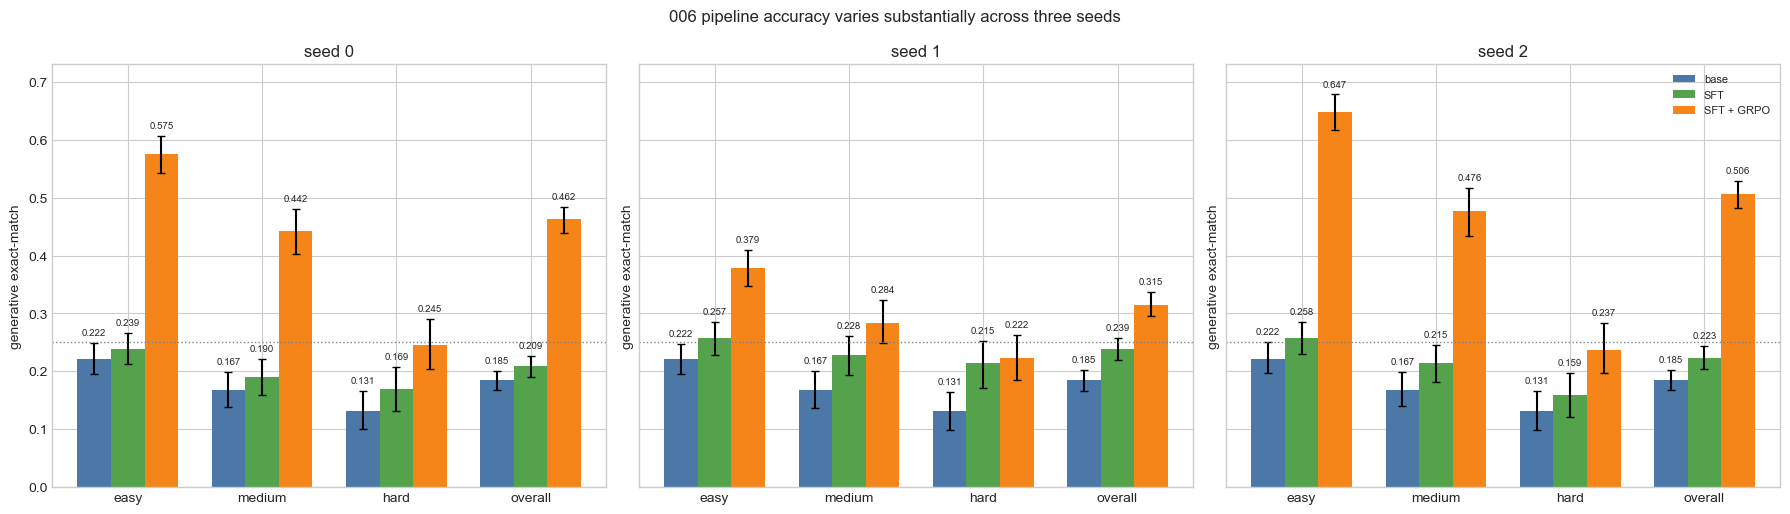

In [83]:
# plot the full base to SFT to GRPO route for each seed
xpos = np.arange(len(GROUPS))
width = 0.25
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), sharey=True)
for ax, seed in zip(axes, SEEDS):
    data = D6[seed]
    for index, condition in enumerate(CONDITIONS):
        values = [group_accuracy(data["preds"][condition], group) for group in GROUPS]
        cis = [group_ci(data["preds"][condition], group, seed=500 + seed * 20 + index * 4 + group_index) for group_index, group in enumerate(GROUPS)]
        errors = [[value - ci[0] for value, ci in zip(values, cis)], [ci[1] - value for value, ci in zip(values, cis)]]
        bars = ax.bar(xpos + (index - 1) * width, values, width, yerr=errors, capsize=3,
                      label=CONDITION_LABELS[condition], color=COLORS[condition])
        labels = [f"{value:.3f}" for value in values]
        ax.bar_label(bars, labels=labels, padding=4, fontsize=7)
    ax.axhline(0.25, color="grey", ls=":", lw=1)
    ax.set_xticks(xpos)
    ax.set_xticklabels(GROUPS)
    ax.set_title(f"seed {seed}")
    ax.set_ylim(0, 0.73)
    ax.set_ylabel("generative exact-match")
axes[-1].legend(fontsize=8)
fig.suptitle("006 pipeline accuracy varies substantially across three seeds")
fig.tight_layout()
save(fig, "fig05_pipeline_accuracy")
plt.show()


In [84]:
# calculate paired GRPO effects separately for each trained seed
GRPO_STATS = {seed: paired_stats(D6[seed]["preds"]["sft"], D6[seed]["preds"]["grpo"], seed=600 + seed) for seed in SEEDS}
grpo_stats_tbl = pd.concat([
    pd.DataFrame(rows).assign(seed=seed)
    for seed, rows in GRPO_STATS.items()
]).set_index(["seed", "group"])
display(grpo_stats_tbl.round({"delta": 4, "ci_lo": 4, "ci_hi": 4, "mcnemar_p": 8, "holm_p_tiers": 8}))


delta   ci_lo   ci_hi  a_only  b_only  mcnemar_p  holm_p_tiers
seed group                                                                   
0    easy     0.3356  0.2981  0.3732      50     345   0.000000      0.000000
     medium   0.2512  0.2085  0.2939      33     186   0.000000      0.000000
     hard     0.0758  0.0278  0.1263      35      65   0.003518      0.003518
     overall  0.2537  0.2282  0.2797     118     596   0.000000           NaN
1    easy     0.1217  0.0842  0.1570      87     194   0.000000      0.000000
     medium   0.0558  0.0131  0.0985      70     104   0.012138      0.024276
     hard     0.0076 -0.0404  0.0556      45      48   0.835846      0.835846
     overall  0.0764  0.0525  0.0998     202     346   0.000000           NaN
2    easy     0.3891  0.3527  0.4243      28     370   0.000000      0.000000
     medium   0.2611  0.2167  0.3054      38     197   0.000000      0.000000
     hard     0.0783  0.0328  0.1237      29      60   0.001335      0.001335
     overall  0.2824  0.2574  0.3079      95     627   0.000000           NaN

saved fig06_grpo_delta


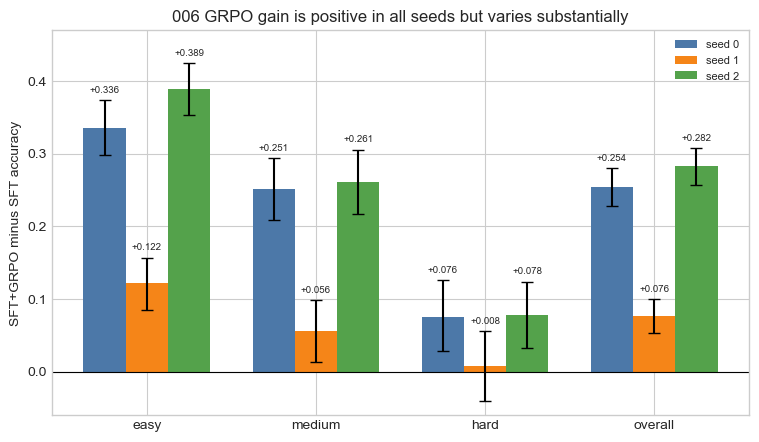

In [85]:
# plot the paired GRPO gain for both artifacts on the same scale
fig, ax = plt.subplots(figsize=(9, 5))
bar_width = 0.25
for index, seed in enumerate(SEEDS):
    rows = GRPO_STATS[seed]
    values = [row["delta"] for row in rows]
    errors = [[row["delta"] - row["ci_lo"] for row in rows], [row["ci_hi"] - row["delta"] for row in rows]]
    bars = ax.bar(xpos + (index - 1) * bar_width, values, bar_width, yerr=errors, capsize=4,
                  color=SEED_COLORS[seed], label=f"seed {seed}")
    labels = [f"{value:+.3f}" for value in values]
    ax.bar_label(bars, labels=labels, padding=4, fontsize=7)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(xpos)
ax.set_xticklabels(GROUPS)
ax.set_ylim(-0.06, 0.47)
ax.set_ylabel("SFT+GRPO minus SFT accuracy")
ax.set_title("006 GRPO gain is positive in all seeds but varies substantially")
ax.legend(fontsize=8)
save(fig, "fig06_grpo_delta")
plt.show()


## 3. What changed

The free-form endpoint moves much more than the letter log-probability probe in every seed.
The result still looks mainly like answer elicitation and format control. Seed 1 reaches a weaker
endpoint than seeds 0 and 2 even though its optimisation diagnostics remain healthy.


saved fig07_generation_vs_probe


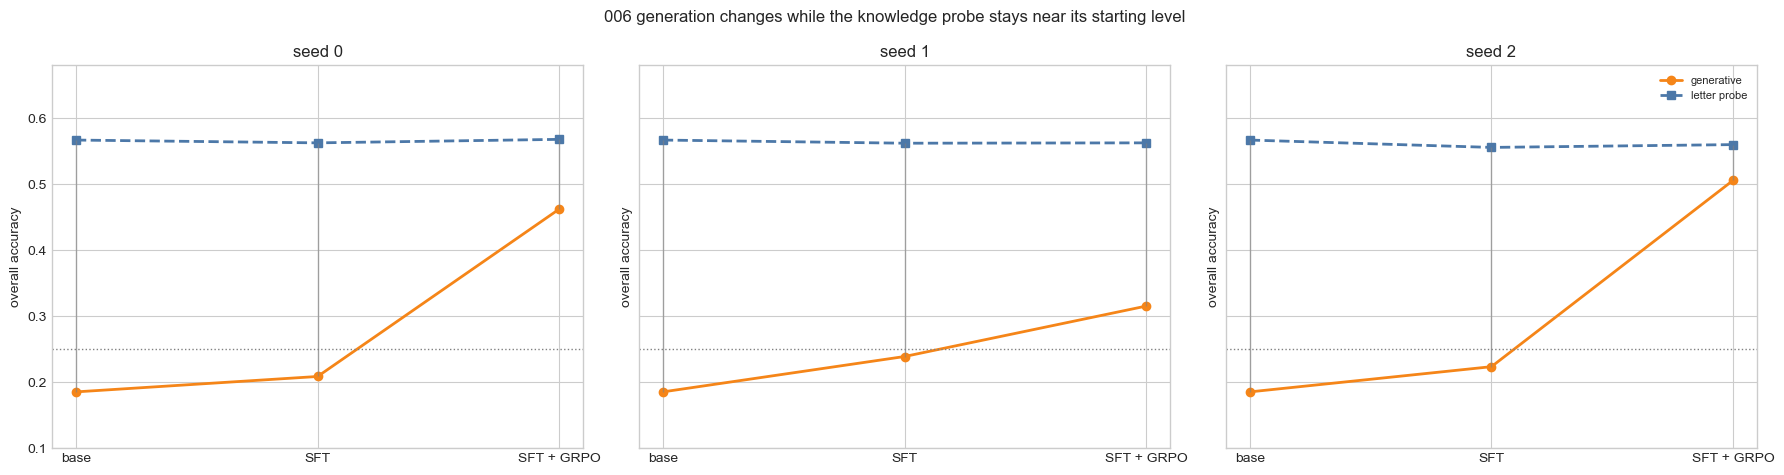

In [86]:
# put generation and the letter probe together for each seed
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)
positions = np.arange(len(CONDITIONS))
for ax, seed in zip(axes, SEEDS):
    gen_values = [overall(D6[seed], condition) for condition in CONDITIONS]
    probe_values = [overall(D6[seed], condition, probe=True) for condition in CONDITIONS]
    ax.plot(positions, gen_values, "o-", color=COLORS["grpo"], lw=2, label="generative")
    ax.plot(positions, probe_values, "s--", color=COLORS["base"], lw=2, label="letter probe")
    for pos, gen_value, probe_value in zip(positions, gen_values, probe_values):
        ax.vlines(pos, gen_value, probe_value, color="grey", lw=1, alpha=0.6)
    ax.axhline(0.25, color="grey", ls=":", lw=1)
    ax.set_xticks(positions)
    ax.set_xticklabels([CONDITION_LABELS[c] for c in CONDITIONS])
    ax.set_title(f"seed {seed}")
    ax.set_ylim(0.1, 0.68)
    ax.set_ylabel("overall accuracy")
axes[-1].legend(fontsize=8)
fig.suptitle("006 generation changes while the knowledge probe stays near its starting level")
fig.tight_layout()
save(fig, "fig07_generation_vs_probe")
plt.show()


saved fig08_eval_diagnostics


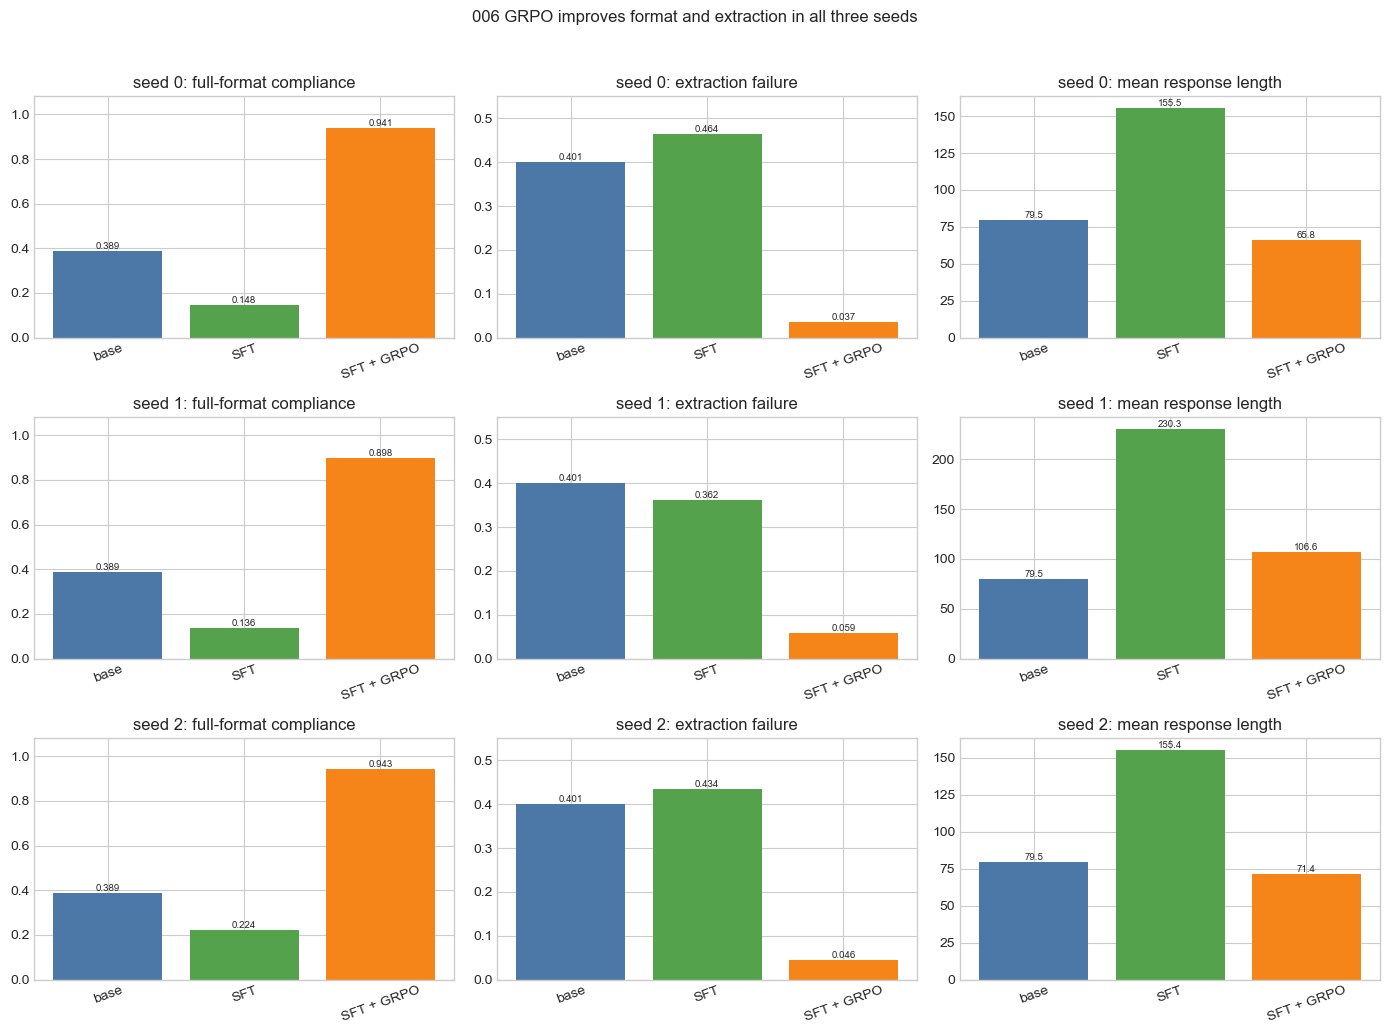

In [87]:
# compare format, extraction failure and response length for all three seeds
metrics = [
    ("format_compliance", "full-format compliance", (0, 1.08)),
    ("extraction_failure_rate", "extraction failure", (0, 0.55)),
    ("mean_len", "mean response length", None),
]
fig, axes = plt.subplots(3, 3, figsize=(14, 10.5))
for row_index, seed in enumerate(SEEDS):
    for ax, (key, title, limits) in zip(axes[row_index], metrics):
        values = [D6[seed]["eval"][condition][key] for condition in CONDITIONS]
        bars = ax.bar([CONDITION_LABELS[c] for c in CONDITIONS], values,
                      color=[COLORS[c] for c in CONDITIONS])
        for bar, value in zip(bars, values):
            label = f"{value:.1f}" if key == "mean_len" else f"{value:.3f}"
            ax.text(bar.get_x() + bar.get_width() / 2, value, label, ha="center", va="bottom", fontsize=7)
        ax.set_title(f"seed {seed}: {title}")
        ax.tick_params(axis="x", rotation=20)
        if limits:
            ax.set_ylim(*limits)
fig.suptitle("006 GRPO improves format and extraction in all three seeds")
fig.tight_layout(rect=[0, 0, 1, 0.96])
save(fig, "fig08_eval_diagnostics")
plt.show()


saved fig09_answer_outcomes


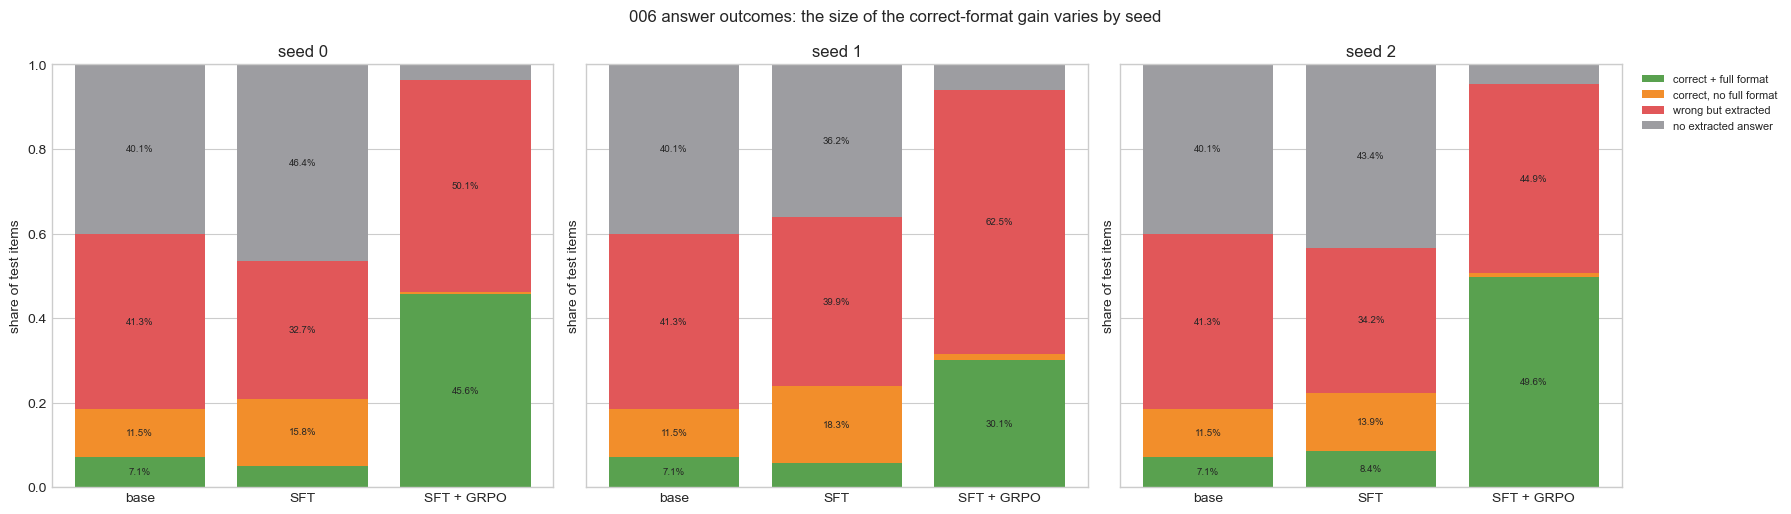

In [88]:
# separate correctness from format and extraction effects in each seed
category_colors = ["#59A14F", "#F28E2B", "#E15759", "#9D9DA1"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), sharey=True)
for ax, seed in zip(axes, SEEDS):
    parts = {condition: outcome_parts(D6[seed]["preds"][condition]) for condition in CONDITIONS}
    categories = list(parts["base"])
    bottom = np.zeros(len(CONDITIONS))
    for category, color in zip(categories, category_colors):
        values = [parts[condition][category] for condition in CONDITIONS]
        ax.bar([CONDITION_LABELS[c] for c in CONDITIONS], values, bottom=bottom, label=category, color=color)
        for index, value in enumerate(values):
            if value >= 0.06:
                ax.text(index, bottom[index] + value / 2, f"{value:.1%}", ha="center", va="center", fontsize=7)
        bottom += values
    ax.set_title(f"seed {seed}")
    ax.set_ylim(0, 1)
    ax.set_ylabel("share of test items")
axes[-1].legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("006 answer outcomes: the size of the correct-format gain varies by seed")
fig.tight_layout()
save(fig, "fig09_answer_outcomes")
plt.show()


saved fig10_subject_grpo_delta


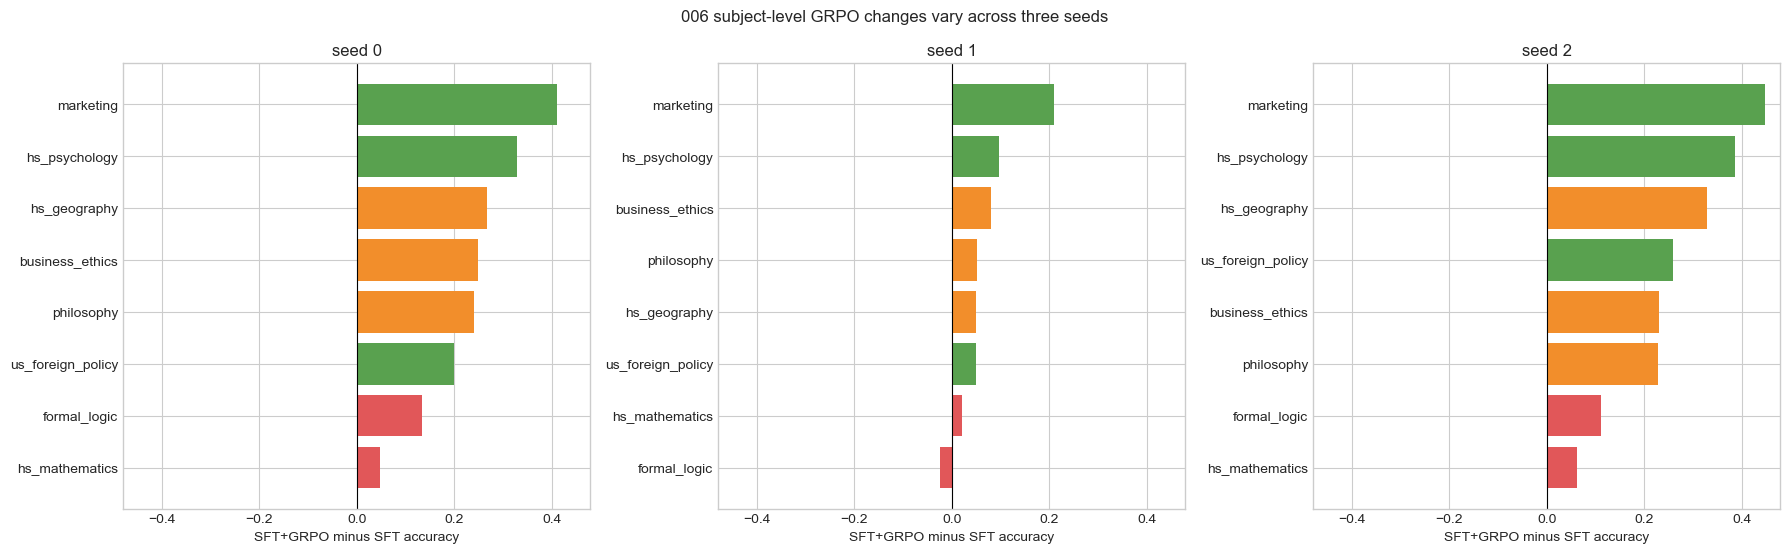

In [89]:
# compare subject-level GRPO changes without hiding the seed difference
SUBJECT_TABLES = {}
all_deltas = []
for seed in SEEDS:
    rows = []
    for subject in D6[seed]["eval"]["sft"]["per_subject_acc"]:
        tier = next(row["tier"] for row in D6[seed]["preds"]["grpo"] if row["subject"] == subject)
        sft_value = D6[seed]["eval"]["sft"]["per_subject_acc"][subject]
        grpo_value = D6[seed]["eval"]["grpo"]["per_subject_acc"][subject]
        rows.append({"subject": subject, "tier": tier, "sft": sft_value, "sft_grpo": grpo_value, "delta": grpo_value - sft_value})
    SUBJECT_TABLES[seed] = pd.DataFrame(rows).set_index("subject").sort_values("delta")
    all_deltas.extend(SUBJECT_TABLES[seed]["delta"].tolist())
limit = max(abs(min(all_deltas)), abs(max(all_deltas))) + 0.03
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6), sharex=True)
for ax, seed in zip(axes, SEEDS):
    table = SUBJECT_TABLES[seed]
    labels = [label.replace("high_school_", "hs_") for label in table.index]
    ax.barh(labels, table["delta"], color=[TIER_COLORS[tier] for tier in table["tier"]])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlim(-limit, limit)
    ax.set_xlabel("SFT+GRPO minus SFT accuracy")
    ax.set_title(f"seed {seed}")
fig.suptitle("006 subject-level GRPO changes vary across three seeds")
fig.tight_layout()
save(fig, "fig10_subject_grpo_delta")
plt.show()


## 4. RQ3 and seed sensitivity

Experiment 005 and experiment 006 seed 0 use the same seed and frozen protocol, so that remains
the matched 0.5B RQ3 artifact comparison. Placing experiment 006 seeds 1 and 2 beside it is useful,
but each comparison also changes the training seed. Their differences from experiment 005 are
shown as sensitivity evidence, not extra estimates of the warm-start effect.


saved fig11_rq3_endpoint_accuracy


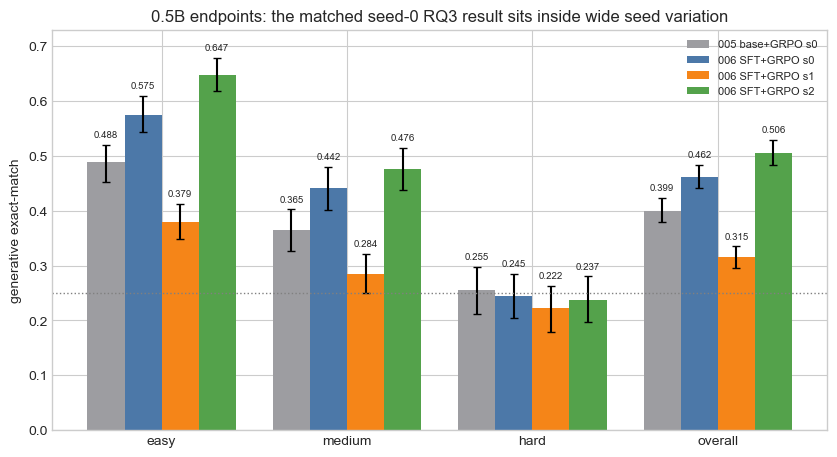

In [90]:
# place the matched RQ3 endpoint beside both seed sensitivity results
rq3_sources = [
    (D5, "005 base+GRPO s0", COLORS["old"]),
    (D6[0], "006 SFT+GRPO s0", SEED_COLORS[0]),
    (D6[1], "006 SFT+GRPO s1", SEED_COLORS[1]),
    (D6[2], "006 SFT+GRPO s2", SEED_COLORS[2]),
]
fig, ax = plt.subplots(figsize=(10, 5.2))
rq3_width = 0.20
for index, (data, label, color) in enumerate(rq3_sources):
    values = [group_accuracy(data["preds"]["grpo"], group) for group in GROUPS]
    cis = [group_ci(data["preds"]["grpo"], group, seed=1100 + index * 10 + group_index) for group_index, group in enumerate(GROUPS)]
    errors = [[value - ci[0] for value, ci in zip(values, cis)], [ci[1] - value for value, ci in zip(values, cis)]]
    bars = ax.bar(xpos + (index - 1.5) * rq3_width, values, rq3_width, yerr=errors, capsize=3, label=label, color=color)
    labels = [f"{value:.3f}" for value in values]
    ax.bar_label(bars, labels=labels, padding=4, fontsize=7)
ax.axhline(0.25, color="grey", ls=":", lw=1)
ax.set_xticks(xpos)
ax.set_xticklabels(GROUPS)
ax.set_ylim(0, 0.73)
ax.set_ylabel("generative exact-match")
ax.set_title("0.5B endpoints: the matched seed-0 RQ3 result sits inside wide seed variation")
ax.legend(fontsize=8)
save(fig, "fig11_rq3_endpoint_accuracy")
plt.show()


In [91]:
# calculate the matched seed 0 RQ3 contrast and both unmatched sensitivity contrasts
RQ3_STATS = {
    0: paired_stats(D5["preds"]["grpo"], D6[0]["preds"]["grpo"], seed=60),
    1: paired_stats(D5["preds"]["grpo"], D6[1]["preds"]["grpo"], seed=61),
    2: paired_stats(D5["preds"]["grpo"], D6[2]["preds"]["grpo"], seed=62),
}
rq3_stats_tbl = pd.concat([
    pd.DataFrame(rows).assign(
        comparison="006 s0 minus 005 s0, matched" if seed == 0 else f"006 s{seed} minus 005 s0, sensitivity"
    )
    for seed, rows in RQ3_STATS.items()
]).set_index(["comparison", "group"])
display(rq3_stats_tbl.round({"delta": 4, "ci_lo": 4, "ci_hi": 4, "mcnemar_p": 8, "holm_p_tiers": 8}))


delta   ci_lo   ci_hi  a_only  \
comparison                       group                                     
006 s0 minus 005 s0, matched     easy     0.0865  0.0466  0.1251     121   
                                 medium   0.0772  0.0312  0.1232      83   
                                 hard    -0.0101 -0.0657  0.0429      64   
                                 overall  0.0632  0.0366  0.0897     268   
006 s1 minus 005 s0, sensitivity easy    -0.1092 -0.1513 -0.0683     230   
                                 medium  -0.0805 -0.1281 -0.0328     135   
                                 hard    -0.0328 -0.0909  0.0253      73   
                                 overall -0.0839 -0.1115 -0.0568     438   
006 s2 minus 005 s0, sensitivity easy     0.1593  0.1206  0.1968      82   
                                 medium   0.1117  0.0673  0.1560      63   
                                 hard    -0.0177 -0.0758  0.0379      70   
                                 overall  0.1067  0.0812  0.1316     215   

                                          b_only     mcnemar_p  holm_p_tiers  
comparison                       group                                        
006 s0 minus 005 s0, matched     easy        197  2.394000e-05      0.000072  
                                 medium      130  1.561130e-03      0.003122  
                                 hard         60  7.877466e-01      0.787747  
                                 overall     387  3.790000e-06           NaN  
006 s1 minus 005 s0, sensitivity easy        134  5.500000e-07      0.000002  
                                 medium       86  1.193190e-03      0.002386  
                                 hard         60  2.980707e-01      0.298071  
                                 overall     280  0.000000e+00           NaN  
006 s2 minus 005 s0, sensitivity easy        222  0.000000e+00      0.000000  
                                 medium      131  1.180000e-06      0.000002  
                                 hard         63  6.030464e-01      0.603046  
                                 overall     416  0.000000e+00           NaN

saved fig12_rq3_paired_delta


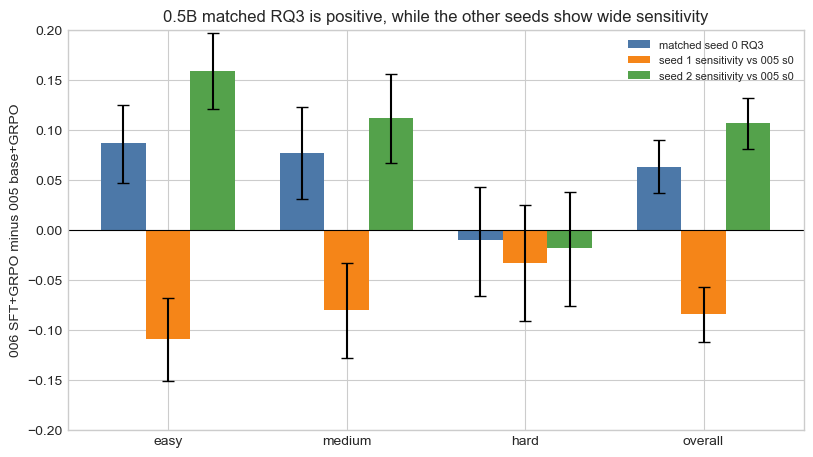

In [92]:
# plot both artifact contrasts but keep their labels methodologically distinct
fig, ax = plt.subplots(figsize=(9.5, 5.2))
for index, seed in enumerate(SEEDS):
    rows = RQ3_STATS[seed]
    values = [row["delta"] for row in rows]
    errors = [[row["delta"] - row["ci_lo"] for row in rows], [row["ci_hi"] - row["delta"] for row in rows]]
    label = "matched seed 0 RQ3" if seed == 0 else f"seed {seed} sensitivity vs 005 s0"
    ax.bar(xpos + (index - 1) * bar_width, values, bar_width, yerr=errors, capsize=4,
           color=SEED_COLORS[seed], label=label)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(xpos)
ax.set_xticklabels(GROUPS)
ax.set_ylim(-0.2, 0.2)
ax.set_ylabel("006 SFT+GRPO minus 005 base+GRPO")
ax.set_title("0.5B matched RQ3 is positive, while the other seeds show wide sensitivity")
ax.legend(fontsize=8)
save(fig, "fig12_rq3_paired_delta")
plt.show()


saved fig13_rq3_subject_delta


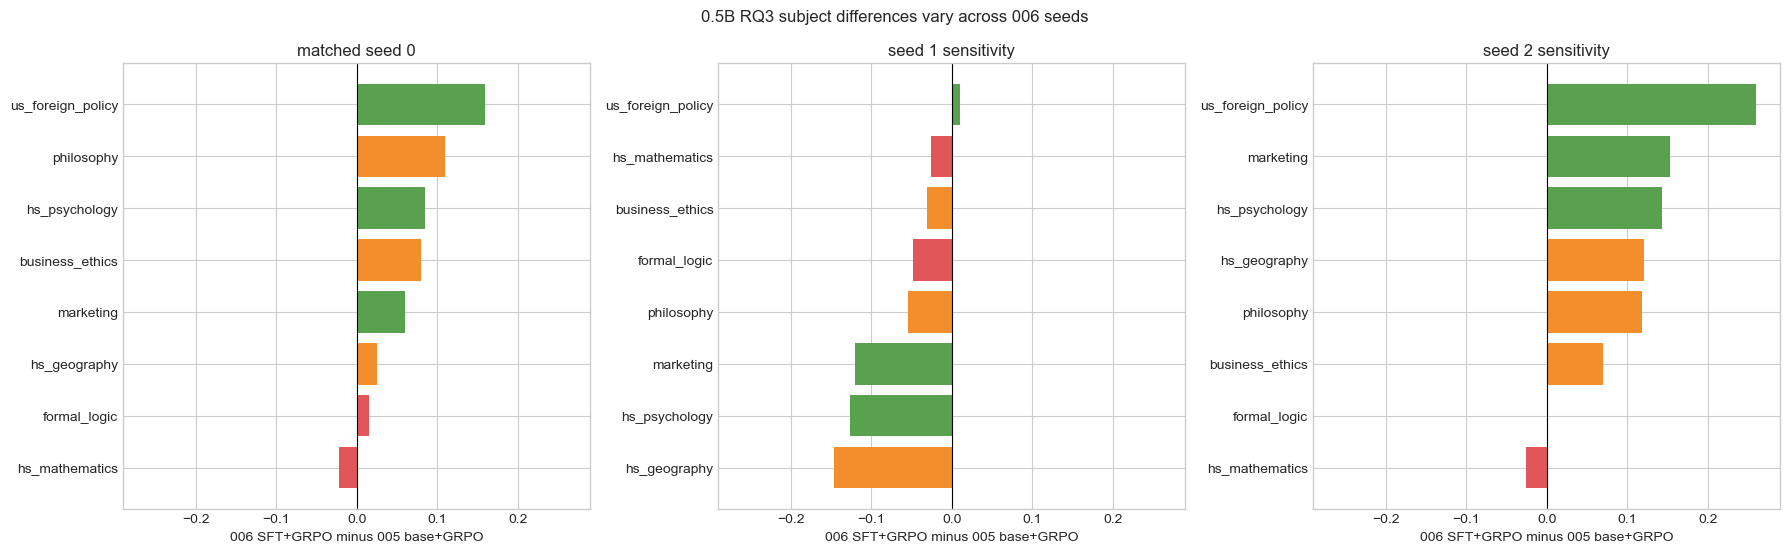

In [93]:
# show which subjects drive the matched result and the sensitivity result
RQ3_SUBJECT_TABLES = {}
all_rq3_deltas = []
for seed in SEEDS:
    rows = []
    for subject in D6[seed]["eval"]["grpo"]["per_subject_acc"]:
        tier = next(row["tier"] for row in D6[seed]["preds"]["grpo"] if row["subject"] == subject)
        base_grpo = D5["eval"]["grpo"]["per_subject_acc"][subject]
        sft_grpo = D6[seed]["eval"]["grpo"]["per_subject_acc"][subject]
        rows.append({"subject": subject, "tier": tier, "base_grpo": base_grpo, "sft_grpo": sft_grpo, "delta": sft_grpo - base_grpo})
    RQ3_SUBJECT_TABLES[seed] = pd.DataFrame(rows).set_index("subject").sort_values("delta")
    all_rq3_deltas.extend(RQ3_SUBJECT_TABLES[seed]["delta"].tolist())
limit = max(abs(min(all_rq3_deltas)), abs(max(all_rq3_deltas))) + 0.03
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6), sharex=True)
for ax, seed in zip(axes, SEEDS):
    table = RQ3_SUBJECT_TABLES[seed]
    labels = [label.replace("high_school_", "hs_") for label in table.index]
    ax.barh(labels, table["delta"], color=[TIER_COLORS[tier] for tier in table["tier"]])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlim(-limit, limit)
    ax.set_xlabel("006 SFT+GRPO minus 005 base+GRPO")
    ax.set_title("matched seed 0" if seed == 0 else f"seed {seed} sensitivity")
fig.suptitle("0.5B RQ3 subject differences vary across 006 seeds")
fig.tight_layout()
save(fig, "fig13_rq3_subject_delta")
plt.show()


## 5. Scale and earlier-run context

The 3B RQ3 pair still has only seed 0. The matched seed-0 comparison across scales is retained,
with the 0.5B seed-1 and seed-2 points shown only as sensitivity markers. This is not a scale-interaction
test and no two-seed 3B mean is available yet.


saved fig14_rq3_by_scale


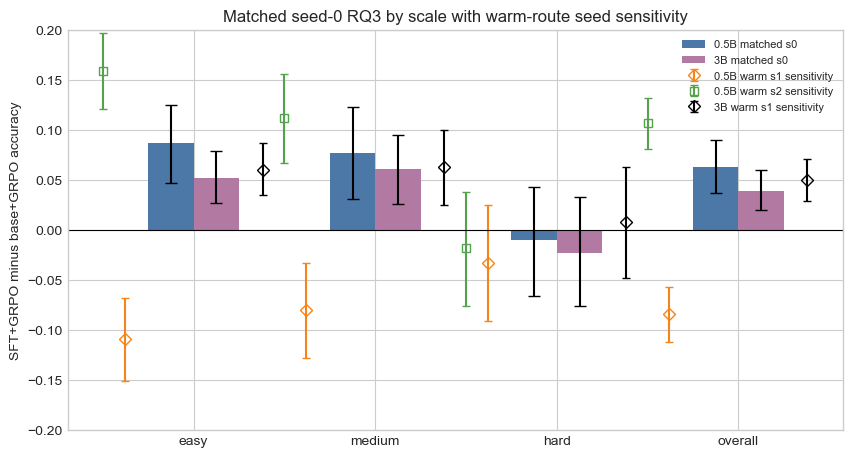

In [94]:
# keep the exact seed-0 scale comparison separate from the extra warm-route seeds
rq3_3b_stats = {seed: paired_stats(D4["preds"]["grpo"], D3[seed]["preds"]["grpo"], seed=34 + seed) for seed in (0, 1)}
fig, ax = plt.subplots(figsize=(10, 5.2))
scale_width = 0.25
for index, (rows, label, color) in enumerate([
    (RQ3_STATS[0], "0.5B matched s0", SEED_COLORS[0]),
    (rq3_3b_stats[0], "3B matched s0", COLORS["other"]),
]):
    values = [row["delta"] for row in rows]
    errors = [[row["delta"] - row["ci_lo"] for row in rows], [row["ci_hi"] - row["delta"] for row in rows]]
    ax.bar(xpos + (index - 0.5) * scale_width, values, scale_width, yerr=errors, capsize=4,
           color=color, label=label)
for seed, offset, marker in [(1, -0.38, "D"), (2, -0.50, "s")]:
    values = [row["delta"] for row in RQ3_STATS[seed]]
    errors = np.array([
        [row["delta"] - row["ci_lo"] for row in RQ3_STATS[seed]],
        [row["ci_hi"] - row["delta"] for row in RQ3_STATS[seed]],
    ])
    ax.errorbar(xpos + offset, values, yerr=errors, fmt=marker, mfc="none", mec=SEED_COLORS[seed],
                ecolor=SEED_COLORS[seed], capsize=3, label=f"0.5B warm s{seed} sensitivity")
values = [row["delta"] for row in rq3_3b_stats[1]]
errors = np.array([
    [row["delta"] - row["ci_lo"] for row in rq3_3b_stats[1]],
    [row["ci_hi"] - row["delta"] for row in rq3_3b_stats[1]],
])
ax.errorbar(xpos + 0.38, values, yerr=errors, fmt="D", mfc="none", mec="black",
            ecolor="black", capsize=3, label="3B warm s1 sensitivity")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(xpos)
ax.set_xticklabels(GROUPS)
ax.set_ylim(-0.2, 0.2)
ax.set_ylabel("SFT+GRPO minus base+GRPO accuracy")
ax.set_title("Matched seed-0 RQ3 by scale with warm-route seed sensitivity")
ax.legend(fontsize=8)
save(fig, "fig14_rq3_by_scale")
plt.show()


saved fig15_002_006_context


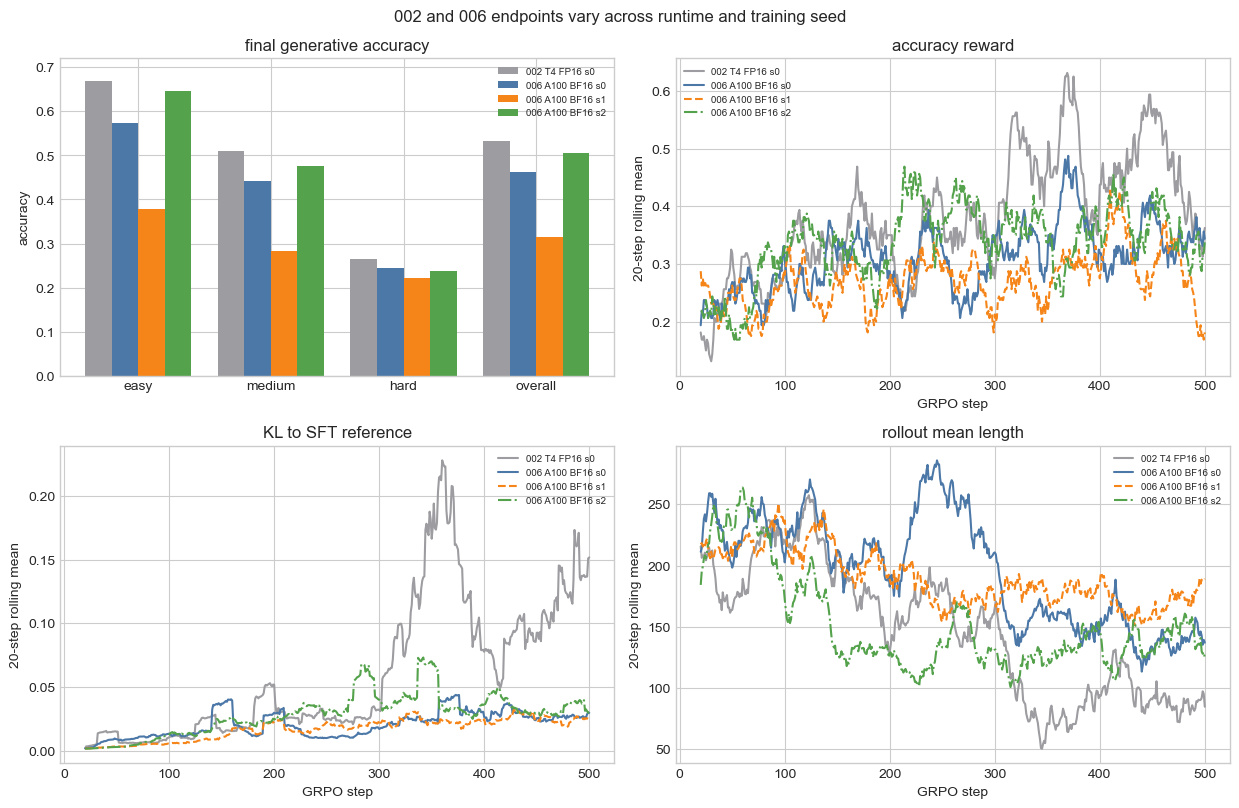

In [95]:
# keep experiment 002 as runtime context and add all three A100 seeds
context_runs = [
    (D2, "002 T4 FP16 s0", COLORS["old"], "-"),
    (D6[0], "006 A100 BF16 s0", SEED_COLORS[0], "-"),
    (D6[1], "006 A100 BF16 s1", SEED_COLORS[1], "--"),
    (D6[2], "006 A100 BF16 s2", SEED_COLORS[2], "-."),
]
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.2))
context_width = 0.20
for index, (data, label, color, style) in enumerate(context_runs):
    values = [group_accuracy(data["preds"]["grpo"], group) for group in GROUPS]
    axes[0, 0].bar(xpos + (index - 1.5) * context_width, values, context_width, label=label, color=color)
axes[0, 0].set_xticks(xpos)
axes[0, 0].set_xticklabels(GROUPS)
axes[0, 0].set_ylim(0, 0.72)
axes[0, 0].set_title("final generative accuracy")
axes[0, 0].set_ylabel("accuracy")
axes[0, 0].legend(fontsize=7)

for ax, key, title in [
    (axes[0, 1], "rewards/accuracy_reward/mean", "accuracy reward"),
    (axes[1, 0], "kl", "KL to SFT reference"),
    (axes[1, 1], "completions/mean_length", "rollout mean length"),
]:
    for data, label, color, style in context_runs:
        x, values = series(data["g"], key)
        ax.plot(x[window - 1:], smooth(values, window), label=label, color=color, ls=style)
    ax.set_title(title)
    ax.set_xlabel("GRPO step")
    ax.set_ylabel("20-step rolling mean")
    ax.legend(fontsize=7)
fig.suptitle("002 and 006 endpoints vary across runtime and training seed")
fig.tight_layout()
save(fig, "fig15_002_006_context")
plt.show()


## 6. Compute and numeric tables

Stage time is reconstructed from `run.log` for consistency. Seeds 1 and 2 reused the shared base
evaluation. Seed 1 used 35.43 Colab compute units. Seed 0 predates compute-unit tracking, and
seed 2 has no recoverable unit total because its starting balance was not saved.


,seed_0_hours,seed_1_hours,seed_2_hours
base_eval,0.409,0.000,0.000
base_logprob_eval,0.003,0.000,0.000
sft_train,0.167,0.172,0.169
sft_eval,1.120,1.146,1.062
sft_logprob_eval,0.004,0.004,0.005
grpo_train,4.328,4.360,3.694
grpo_eval,0.577,0.876,0.661
grpo_logprob_eval,0.004,0.004,0.005
total,6.613,6.562,5.597


saved fig16_compute_timing


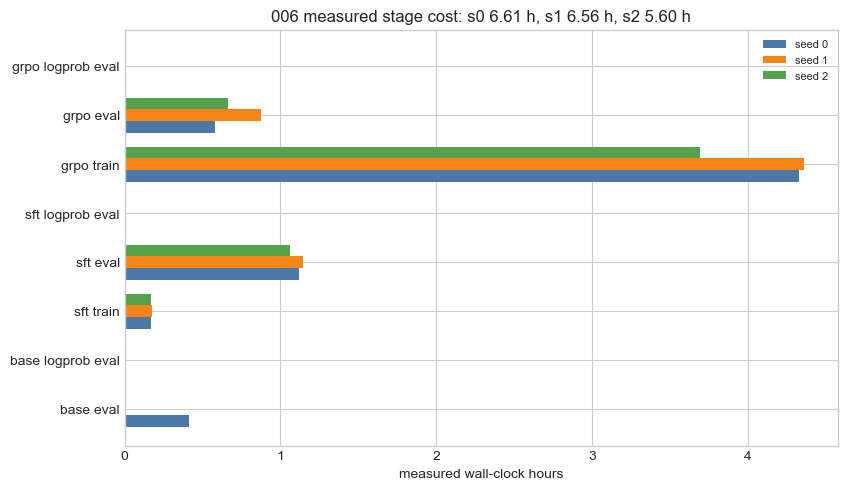

Colab compute units: seed 1 = 35.43; seed 2 unavailable because cu_before was not saved


In [96]:
# compare measured stage time without counting reused base evaluations
stage_order = ["base_eval", "base_logprob_eval", "sft_train", "sft_eval", "sft_logprob_eval", "grpo_train", "grpo_eval", "grpo_logprob_eval"]
compute_tbl = pd.DataFrame({
    f"seed_{seed}_hours": [RUN_TIMINGS[seed].get(stage, 0) / 3600 for stage in stage_order]
    for seed in SEEDS
}, index=stage_order)
compute_tbl.loc["total"] = compute_tbl.sum()
display(compute_tbl.round(3))

plot_tbl = compute_tbl.drop(index="total")
y = np.arange(len(plot_tbl))
fig, ax = plt.subplots(figsize=(9.2, 5.4))
bar_height = 0.24
for index, seed in enumerate(SEEDS):
    values = plot_tbl[f"seed_{seed}_hours"].to_numpy()
    ax.barh(y + (index - 1) * bar_height, values, bar_height, color=SEED_COLORS[seed], label=f"seed {seed}")
ax.set_yticks(y)
ax.set_yticklabels([label.replace("_", " ") for label in plot_tbl.index])
ax.set_xlabel("measured wall-clock hours")
totals = ", ".join(f"s{seed} {compute_tbl.loc['total', f'seed_{seed}_hours']:.2f} h" for seed in SEEDS)
ax.set_title(f"006 measured stage cost: {totals}")
ax.legend(fontsize=8)
save(fig, "fig16_compute_timing")
plt.show()
print("Colab compute units: seed 1 = 35.43; seed 2 unavailable because cu_before was not saved")


In [97]:
# keep generative and probe accuracy together for all three seeds
accuracy_rows = []
for seed in SEEDS:
    for condition in CONDITIONS:
        row = {"seed": seed, "condition": CONDITION_LABELS[condition]}
        for tier in TIERS:
            row[f"gen_{tier}"] = group_accuracy(D6[seed]["preds"][condition], tier)
            row[f"probe_{tier}"] = group_accuracy(D6[seed]["lp_preds"][condition], tier)
        row["gen_overall"] = overall(D6[seed], condition)
        row["probe_overall"] = overall(D6[seed], condition, probe=True)
        accuracy_rows.append(row)
accuracy_tbl = pd.DataFrame(accuracy_rows).set_index(["seed", "condition"]).round(4)
display(accuracy_tbl)


gen_easy  probe_easy  gen_medium  probe_medium  gen_hard  \
seed condition                                                              
0    base          0.2218      0.6871      0.1675        0.5172    0.1313   
     SFT           0.2389      0.6758      0.1905        0.5255    0.1692   
     SFT + GRPO    0.5745      0.6883      0.4417        0.5255    0.2449   
1    base          0.2218      0.6871      0.1675        0.5172    0.1313   
     SFT           0.2571      0.6769      0.2282        0.5172    0.2146   
     SFT + GRPO    0.3788      0.6803      0.2841        0.5123    0.2222   
2    base          0.2218      0.6871      0.1675        0.5172    0.1313   
     SFT           0.2582      0.6769      0.2151        0.5090    0.1591   
     SFT + GRPO    0.6473      0.6837      0.4762        0.5140    0.2374   

                 probe_hard  gen_overall  probe_overall  
seed condition                                           
0    base            0.3763       0.1852         0.5669  
     SFT             0.3687       0.2086         0.5626  
     SFT + GRPO      0.3662       0.4623         0.5679  
1    base            0.3763       0.1852         0.5669  
     SFT             0.3763       0.2389         0.5621  
     SFT + GRPO      0.3788       0.3153         0.5626  
2    base            0.3763       0.1852         0.5669  
     SFT             0.3586       0.2235         0.5557  
     SFT + GRPO      0.3561       0.5058         0.5600

In [98]:
# keep the main output diagnostics in one table
rows = []
for seed in SEEDS:
    for condition in CONDITIONS:
        predictions = D6[seed]["preds"][condition]
        rows.append({
            "seed": seed,
            "condition": CONDITION_LABELS[condition],
            "format_compliance": D6[seed]["eval"][condition]["format_compliance"],
            "extraction_failure": D6[seed]["eval"][condition]["extraction_failure_rate"],
            "mean_length": D6[seed]["eval"][condition]["mean_len"],
            "at_512_token_cap": np.mean([row["n_tokens"] >= 512 for row in predictions]),
            "correct_and_full_format": np.mean([row["correct"] and row["format_ok"] for row in predictions]),
        })
diagnostics_tbl = pd.DataFrame(rows).set_index(["seed", "condition"]).round(4)
display(diagnostics_tbl)


format_compliance  extraction_failure  mean_length  \
seed condition                                                        
0    base                   0.3891              0.4013      79.4501   
     SFT                    0.1481              0.4644     155.5494   
     SFT + GRPO             0.9406              0.0366      65.8455   
1    base                   0.3891              0.4013      79.4501   
     SFT                    0.1364              0.3620     230.3482   
     SFT + GRPO             0.8976              0.0594     106.5589   
2    base                   0.3891              0.4013      79.4501   
     SFT                    0.2240              0.4342     155.3912   
     SFT + GRPO             0.9432              0.0456      71.4124   

                 at_512_token_cap  correct_and_full_format  
seed condition                                              
0    base                  0.0610                   0.0706  
     SFT                   0.1359                   0.0510  
     SFT + GRPO            0.0435                   0.4559  
1    base                  0.0610                   0.0706  
     SFT                   0.2399                   0.0563  
     SFT + GRPO            0.0780                   0.3010  
2    base                  0.0610                   0.0706  
     SFT                   0.1354                   0.0844  
     SFT + GRPO            0.0451                   0.4963

In [99]:
# put all available warm-route seeds beside the exact seed-0 RQ3 pairs
comparison_rows = []
for experiment, scale, route, seed, data in [
    ("005", "0.5B", "base + GRPO", 0, D5),
    ("006", "0.5B", "SFT + GRPO", 0, D6[0]),
    ("006", "0.5B", "SFT + GRPO", 1, D6[1]),
    ("006", "0.5B", "SFT + GRPO", 2, D6[2]),
    ("004", "3B", "base + GRPO", 0, D4),
    ("003", "3B", "SFT + GRPO", 0, D3[0]),
    ("003", "3B", "SFT + GRPO", 1, D3[1]),
]:
    row = {
        "experiment": experiment,
        "scale": scale,
        "route": route,
        "seed": seed,
        "gpu": data["man"]["gpu"]["device"],
        "overall": overall(data, "grpo"),
        "format": data["eval"]["grpo"]["format_compliance"],
        "extraction_failure": data["eval"]["grpo"]["extraction_failure_rate"],
    }
    row.update({tier: group_accuracy(data["preds"]["grpo"], tier) for tier in TIERS})
    comparison_rows.append(row)
comparison_tbl = pd.DataFrame(comparison_rows).set_index(["experiment", "seed"]).round(4)
display(comparison_tbl)


scale        route                    gpu  overall  format  \
experiment seed                                                              
005        0     0.5B  base + GRPO  NVIDIA A100-SXM4-40GB   0.3992  0.0175   
006        0     0.5B   SFT + GRPO  NVIDIA A100-SXM4-40GB   0.4623  0.9406   
           1     0.5B   SFT + GRPO  NVIDIA A100-SXM4-40GB   0.3153  0.8976   
           2     0.5B   SFT + GRPO  NVIDIA A100-SXM4-40GB   0.5058  0.9432   
004        0       3B  base + GRPO  NVIDIA A100-SXM4-80GB   0.6768  0.9374   
003        0       3B   SFT + GRPO  NVIDIA A100-SXM4-80GB   0.7160  0.9644   
           1       3B   SFT + GRPO  NVIDIA A100-SXM4-80GB   0.7266  0.9544   

                 extraction_failure    easy  medium    hard  
experiment seed                                              
005        0                 0.0823  0.4881  0.3645  0.2551  
006        0                 0.0366  0.5745  0.4417  0.2449  
           1                 0.0594  0.3788  0.2841  0.2222  
           2                 0.0456  0.6473  0.4762  0.2374  
004        0                 0.0494  0.7770  0.6190  0.5429  
003        0                 0.0297  0.8294  0.6798  0.5202  
           1                 0.0361  0.8373  0.6814  0.5505

In [100]:
# keep the subject values behind the subject plots
for seed in SEEDS:
    print(f"006 SFT to GRPO subject deltas, seed {seed}")
    display(SUBJECT_TABLES[seed].round(4))
    print(f"006 minus 005 subject deltas, seed {seed}")
    display(RQ3_SUBJECT_TABLES[seed].round(4))


006 SFT to GRPO subject deltas, seed 0


,tier,sft,sft_grpo,delta
subject,,,,
high_school_mathematics,hard,0.1667,0.2148,0.0481
formal_logic,hard,0.1746,0.3095,0.1349
us_foreign_policy,easy,0.3700,0.5700,0.2000
philosophy,medium,0.1833,0.4244,0.2412
business_ethics,medium,0.1900,0.4400,0.2500
high_school_geography,medium,0.2020,0.4697,0.2677
high_school_psychology,easy,0.2239,0.5523,0.3284
marketing,easy,0.2179,0.6282,0.4103


006 minus 005 subject deltas, seed 0


,tier,base_grpo,sft_grpo,delta
subject,,,,
high_school_mathematics,hard,0.2370,0.2148,-0.0222
formal_logic,hard,0.2937,0.3095,0.0159
high_school_geography,medium,0.4444,0.4697,0.0253
marketing,easy,0.5684,0.6282,0.0598
business_ethics,medium,0.3600,0.4400,0.0800
high_school_psychology,easy,0.4679,0.5523,0.0844
philosophy,medium,0.3151,0.4244,0.1093
us_foreign_policy,easy,0.4100,0.5700,0.1600


006 SFT to GRPO subject deltas, seed 1


,tier,sft,sft_grpo,delta
subject,,,,
formal_logic,hard,0.2698,0.2460,-0.0238
high_school_mathematics,hard,0.1889,0.2111,0.0222
us_foreign_policy,easy,0.3700,0.4200,0.0500
high_school_geography,medium,0.2475,0.2980,0.0505
philosophy,medium,0.2090,0.2605,0.0514
business_ethics,medium,0.2500,0.3300,0.0800
high_school_psychology,easy,0.2440,0.3413,0.0972
marketing,easy,0.2393,0.4487,0.2094


... (2 outputs left out)

006 SFT to GRPO subject deltas, seed 2


,tier,sft,sft_grpo,delta
subject,,,,
high_school_mathematics,hard,0.1481,0.2111,0.0630
formal_logic,hard,0.1825,0.2937,0.1111
philosophy,medium,0.2058,0.4341,0.2283
business_ethics,medium,0.2000,0.4300,0.2300
us_foreign_policy,easy,0.4100,0.6700,0.2600
high_school_geography,medium,0.2374,0.5657,0.3283
high_school_psychology,easy,0.2239,0.6110,0.3872
marketing,easy,0.2735,0.7222,0.4487


006 minus 005 subject deltas, seed 2


,tier,base_grpo,sft_grpo,delta
subject,,,,
high_school_mathematics,hard,0.2370,0.2111,-0.0259
formal_logic,hard,0.2937,0.2937,0.0000
business_ethics,medium,0.3600,0.4300,0.0700
philosophy,medium,0.3151,0.4341,0.1190
high_school_geography,medium,0.4444,0.5657,0.1212
high_school_psychology,easy,0.4679,0.6110,0.1431
marketing,easy,0.5684,0.7222,0.1538
us_foreign_policy,easy,0.4100,0.6700,0.2600


## Cross-referenced conclusion

All three runs finished correctly. GRPO improves over its own SFT checkpoint in every seed, but
the size varies: +25.4 points in seed 0, +7.6 points in seed 1 and +28.2 points in seed 2. The
final GRPO scores are 46.2%, 31.5% and 50.6%. The mean gain is 20.4 points with an 11.2-point
sample standard deviation, so the 7.6 to 28.2-point range should stay visible.

The mechanism result is more stable than the endpoint size. The letter probe remains near 56%
in all three runs. GRPO raises format compliance to 94.1%, 89.8% and 94.3%, while the SFT
checkpoints start at 14.8%, 13.6% and 22.4%. This supports answer elicitation and format learning
rather than a large increase in stored MMLU knowledge.

The matched RQ3 result is still seed 0 only: experiment 006 beats experiment 005 by 6.3 points
overall. Relative to that same seed-0 artifact, seed 1 is 8.4 points lower and seed 2 is 10.7
points higher. Both sensitivity comparisons change the training seed. They show that one matched
pair is not enough for a procedure-level warm-start claim.

The exact 3B RQ3 contrast also remains seed 0 only because experiment 004 has no matching second
seed. Experiment 003 seed 1 does replicate the warm-route endpoint: SFT+GRPO reaches 72.7%,
compared with 71.6% in seed 0, and its within-run GRPO gain is 21.7 points compared with 18.2
points in seed 0. Relative to the same experiment 004 seed-0 endpoint, the two warm-route results
are +3.9 and +5.0 points. This makes the warm-route procedure less provisional, but it is not a
second matched RQ3 contrast. The later MC-SFT controls in experiments 007 and 008 reach
53.4% and 53.3% on average at 0.5B across three generative seeds, above the 42.8% three-seed
006 mean. This strengthens the supervised control, while a procedure-level method comparison
still has only one exactly matched seed-0 pair.
